Creating a neighborhood graph using the X_pca data we created. (X_pca stores the locations of each cell along each pc)

In [2]:
import scanpy as sc

adata = sc.read_h5ad("data/processed_pbmc.h5ad")

c:\Users\murak\miniconda3\envs\scRNA\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 2.2.0 when it was built against 2.1.0, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


In [3]:
# cells that have similar expression should be near each other in a graph 
# we're going with 10 pcs to use some of the info the later pcs give too
# n_neighbors means find the 10 most similar cells for each cell, not all cells are shown
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10) 
adata.obsp.keys() # obsp means observation pair, how pairs of cells relate to each other 


KeysView(PairwiseArrays with keys: distances, connectivities)

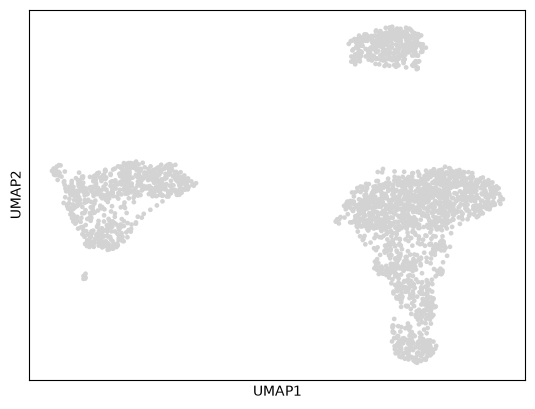

In [4]:
# UMAP 
sc.tl.umap(adata)
sc.pl.umap(adata)

In [5]:
sc.tl.leiden(adata)
adata.obs.head()

C:\Users\murak\AppData\Local\Temp\ipykernel_14800\2658440798.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata)


,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,leiden
index,,,,,,,,,,,,
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,47.748864,63.279637,74.969021,88.393226,75.0,4.330733,3.097893,4
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,45.502753,61.023863,71.813176,82.622884,190.0,5.252274,3.875179,0
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,41.314703,53.794856,65.449349,79.961893,34.0,3.555348,1.079708,7
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,39.029936,52.898825,66.691929,82.569155,52.0,3.970292,1.970443,5
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,44.852192,55.657492,67.176351,97.757390,14.0,2.708050,1.427115,8


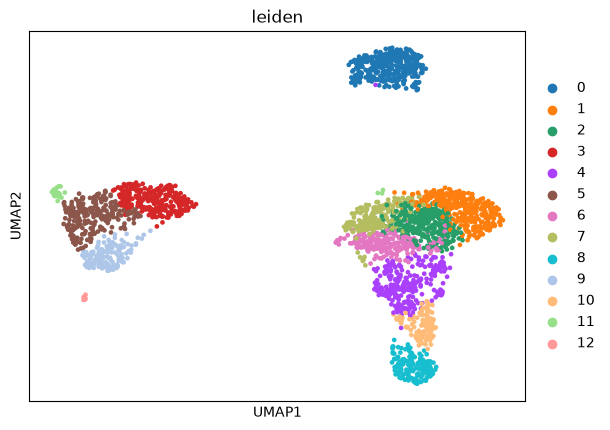

In [6]:
sc.pl.umap(
    adata, 
    color="leiden"
)

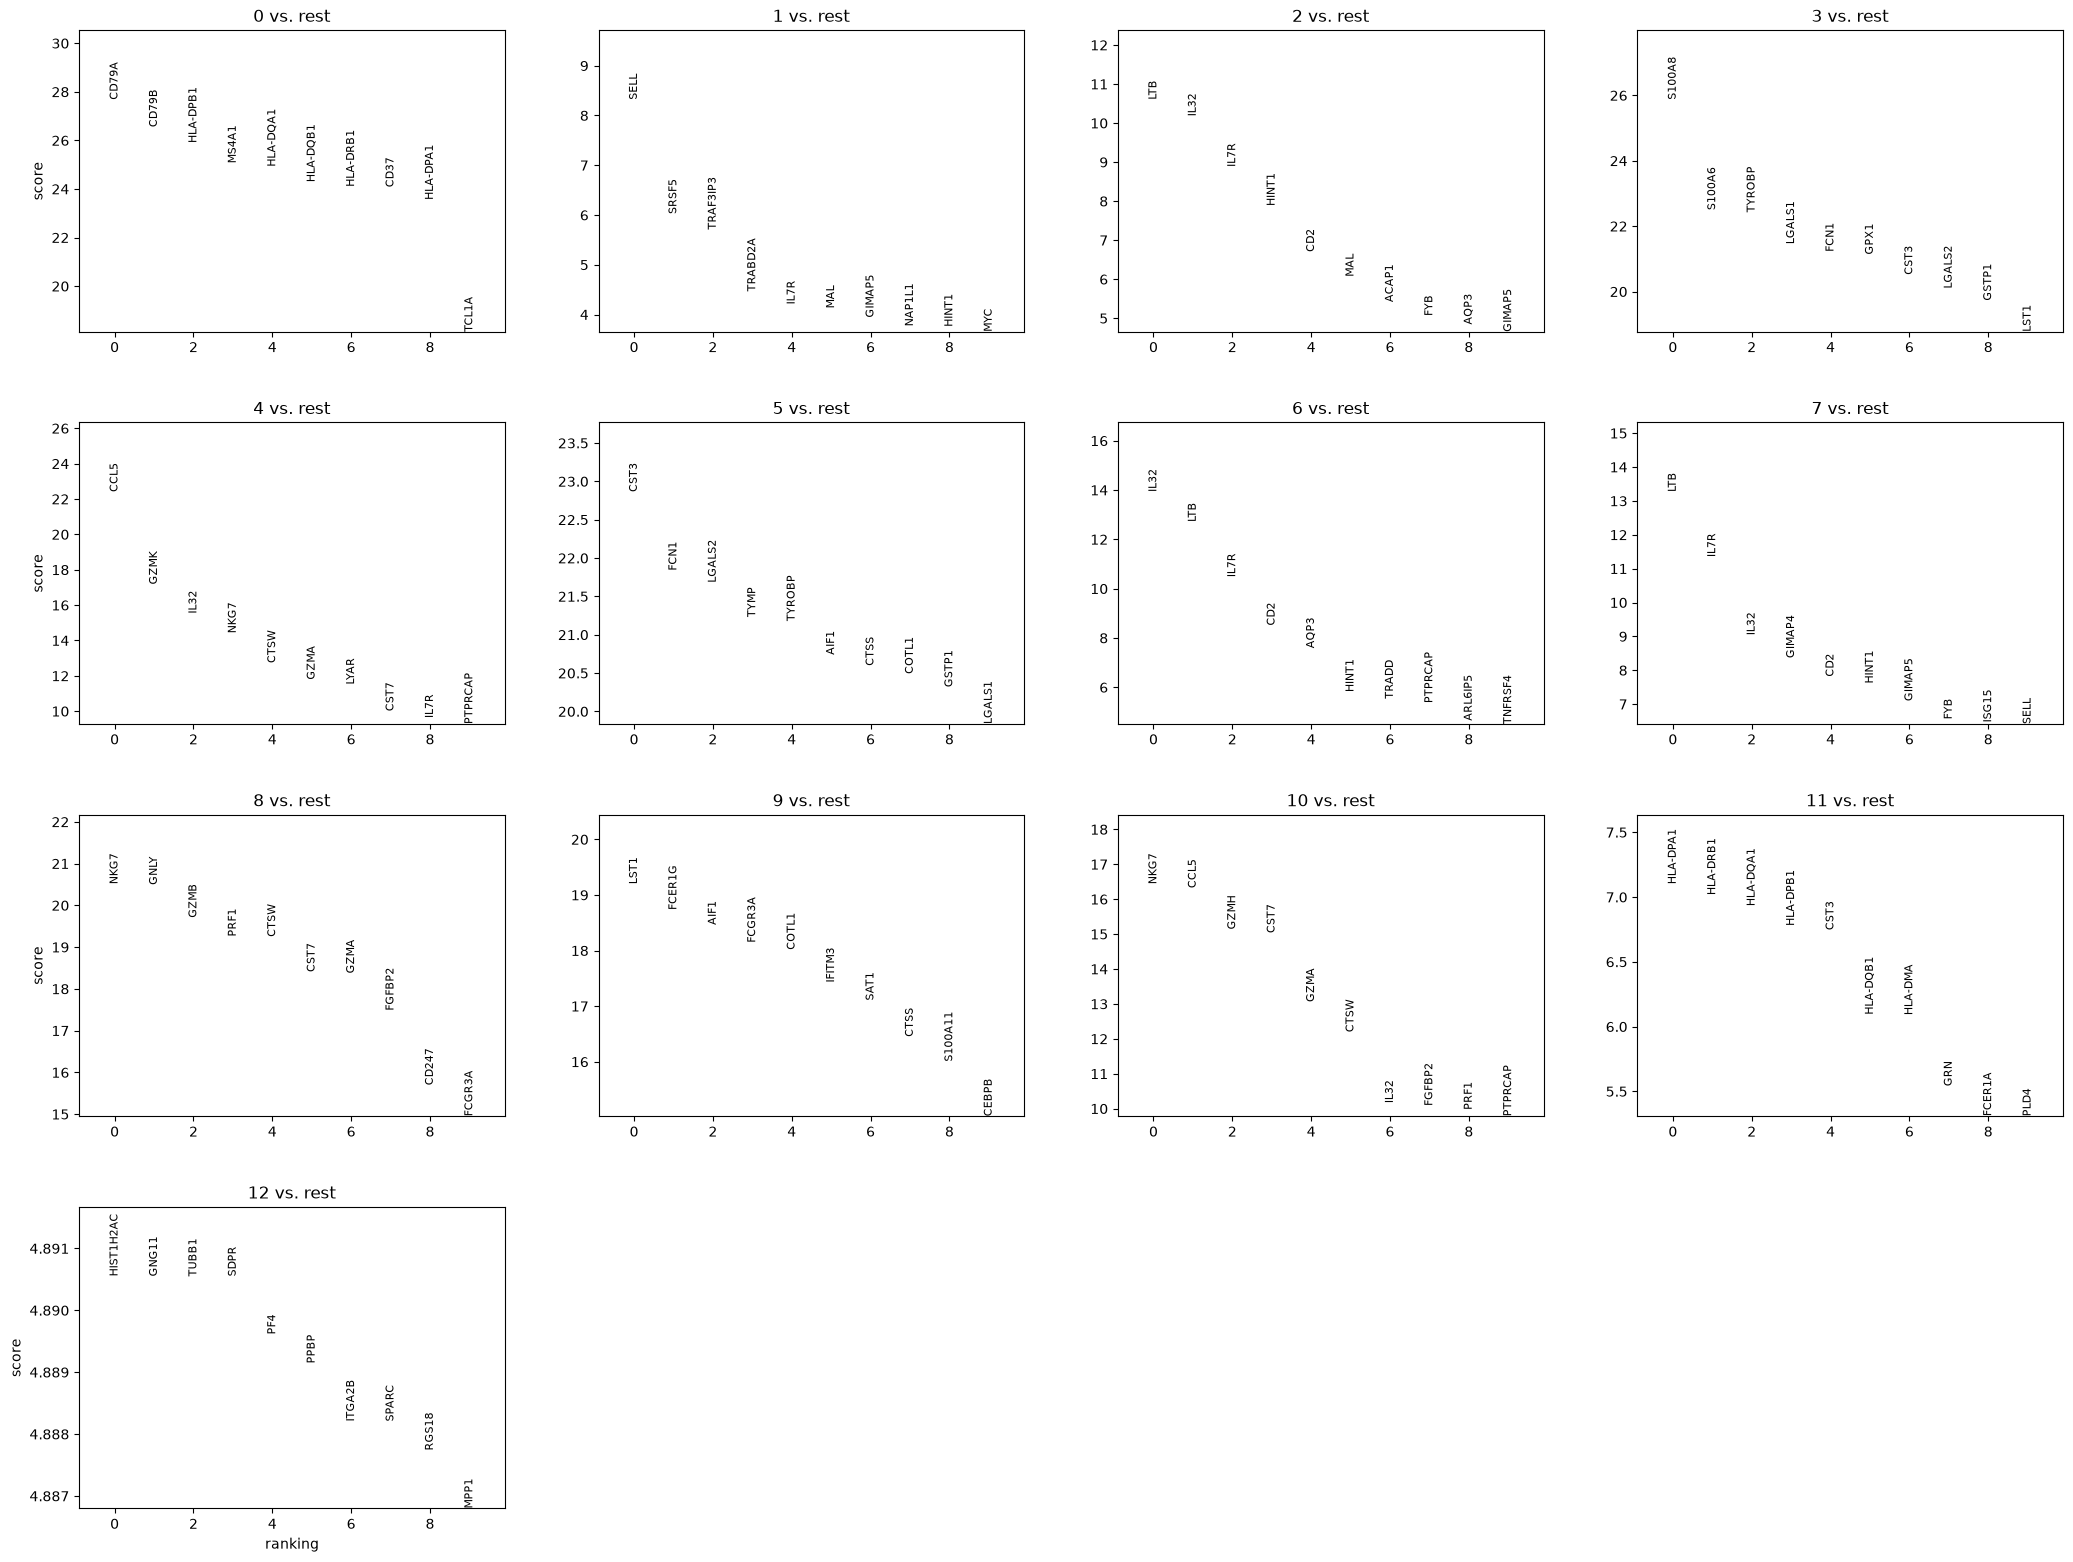

In [7]:
# this will tell us for each cluster which gene is highest expressed
sc.tl.rank_genes_groups(
    adata, 
    groupby="leiden", 
    method="wilcoxon"
)
sc.pl.rank_genes_groups(
    adata, 
    n_genes=10, 
    sharey=False
)

In [8]:
result = sc.get.rank_genes_groups_df(
    adata, 
    group=None
)
result.head()

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
2,0,HLA-DPB1,25.892418,4.072172,8.106834e-148,5.369426e-145
3,0,MS4A1,25.057699,6.423985,1.439133e-138,7.148895e-136
4,0,HLA-DQA1,24.917364,5.313763,4.824401e-137,1.917217e-134


In [ ]:
top5 = (
    result
    .sort_values(["group", "scores"], ascending=[True, False]) # sort group in ascending order FIRST then scores in descending SECOND
    .groupby("group") # "groups" each cluster
    .head(2) # shows top 2 genes for each group
)
top5


C:\Users\murak\AppData\Local\Temp\ipykernel_14800\2731435231.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group") # groups each cluster


,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
1987,1,SELL,8.316856,1.169984,9.032714e-17,8.158184e-15
1988,1,SRSF5,6.020982,0.620136,1.733623e-09,9.310023e-08
3974,2,LTB,10.598515,1.594969,3.027500e-26,1.503911e-23
3975,2,IL32,10.173858,1.634788,2.594248e-24,7.363957e-22
5961,3,S100A8,25.866749,7.151405,1.576831e-147,3.133164e-144
5962,3,S100A6,22.491323,2.835183,5.047189e-112,5.014383e-109
7948,4,CCL5,22.399811,5.324578,3.952490e-111,7.853598e-108
7949,4,GZMK,17.170605,5.657723,4.407997e-66,4.379345e-63


In [10]:
top5[["group", "names"]] # pulls a subset of the df with cols group and names

,group,names
0,0,CD79A
1,0,CD79B
2,0,HLA-DPB1
3,0,MS4A1
4,0,HLA-DQA1
...,...,...
23844,12,HIST1H2AC
23845,12,GNG11
23846,12,TUBB1
23847,12,SDPR


In [11]:
characteristic_genes = {}
for i in range(13):
    genes = top5[top5["group"] == str(i)]["names"].tolist()
    characteristic_genes[i] = genes

print(characteristic_genes)

{0: ['CD79A', 'CD79B', 'HLA-DPB1', 'MS4A1', 'HLA-DQA1'], 1: ['SELL', 'SRSF5', 'TRAF3IP3', 'TRABD2A', 'IL7R'], 2: ['LTB', 'IL32', 'IL7R', 'HINT1', 'CD2'], 3: ['S100A8', 'S100A6', 'TYROBP', 'LGALS1', 'FCN1'], 4: ['CCL5', 'GZMK', 'IL32', 'NKG7', 'CTSW'], 5: ['CST3', 'FCN1', 'LGALS2', 'TYMP', 'TYROBP'], 6: ['IL32', 'LTB', 'IL7R', 'CD2', 'AQP3'], 7: ['LTB', 'IL7R', 'IL32', 'GIMAP4', 'CD2'], 8: ['NKG7', 'GNLY', 'GZMB', 'PRF1', 'CTSW'], 9: ['LST1', 'FCER1G', 'AIF1', 'FCGR3A', 'COTL1'], 10: ['NKG7', 'CCL5', 'GZMH', 'CST7', 'GZMA'], 11: ['HLA-DPA1', 'HLA-DRB1', 'HLA-DQA1', 'HLA-DPB1', 'CST3'], 12: ['HIST1H2AC', 'GNG11', 'TUBB1', 'SDPR', 'PF4']}


In [12]:
cluster_to_celltype = {
    "0": "B cell",
    "1": "T cell",
    "2": "T cell",
    "3": "Classical monocyte",
    "4": "Memory/effector T cell",
    "5": "Classical monocyte",
    "6": "T cell",
    "7": "T cell",
    "8": "NK cell",
    "9": "FCGR3A+ monocyte",
    "10": "NK/cytotoxic lymphocyte",
    "11": "Dendritic/APC",
    "12": "Megakaryocyte",
}
# map the cluster numbers to the new labels
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_celltype)
adata.obs[["leiden", "cell_type"]].head(20)

,leiden,cell_type
index,,
AAACATACAACCAC-1,4,Memory/effector T cell
AAACATTGAGCTAC-1,0,B cell
AAACATTGATCAGC-1,7,T cell
AAACCGTGCTTCCG-1,5,Classical monocyte
AAACCGTGTATGCG-1,8,NK cell
AAACGCACTGGTAC-1,2,T cell
AAACGCTGACCAGT-1,4,Memory/effector T cell
AAACGCTGGTTCTT-1,4,Memory/effector T cell
AAACGCTGTAGCCA-1,4,Memory/effector T cell


In [13]:
# for each cell type, count how many cells there are
adata.obs["cell_type"].value_counts()

cell_type
T cell                     1075
Classical monocyte          509
B cell                      338
Memory/effector T cell      247
NK cell                     158
FCGR3A+ monocyte            141
NK/cytotoxic lymphocyte     117
Dendritic/APC                23
Megakaryocyte                 8
Name: count, dtype: int64

In [14]:
adata.write("data/annotated_pbmc.h5ad")